# T02 - Cleaning (phần Python)
**SQL (`01_cleaning.sql`) đã làm:** bỏ dòng thiếu giá/năm sản xuất, đổi giá sang triệu, tính tuổi xe, lọc tin spam, tạo cờ văn bản, đổi mã sang chữ, chuẩn hóa tỉnh, bỏ ODO = 0, bỏ trùng xe.

**Python làm tiếp:** (1) quyết định có cắt giá không, (2) lọc ODO bất thường theo km mỗi năm, (3) xuất `cars_cleaned.csv`.

Cài một lần: `pip install pandas numpy sqlalchemy pyodbc matplotlib ipykernel`

In [7]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

SERVER = "localhost\\TEST"
engine = create_engine(
    f"mssql+pyodbc://@{SERVER}/UsedCars"
    "?driver=ODBC+Driver+18+for+SQL+Server"
    "&trusted_connection=yes&TrustServerCertificate=yes"
)

raw_rows = pd.read_sql("SELECT COUNT(*) AS n FROM cars_raw", engine)["n"][0]
df = pd.read_sql("SELECT * FROM cars_clean", engine)
rows_from_sql = len(df)
print("Số dòng thô:", raw_rows, "| sau SQL:", rows_from_sql)
print("ODO = 0 hoặc thiếu :", ((df["odo_km"] == 0) | df["odo_km"].isna()).sum())

Số dòng thô: 15000 | sau SQL: 13819
ODO = 0 hoặc thiếu : 0


In [1]:
df.corr()

NameError: name 'df' is not defined

## 1. Giá: có nên cắt ngoại lai không?
IQR = Q3 - Q1 (Q1, Q3 là mốc 25% và 75%). Giá trị nằm ngoài khoảng **Q1 - 1,5×IQR đến Q3 + 1,5×IQR** bị coi là ngoại lai. Ở bước này chỉ **đánh dấu** để xem, chưa xóa gì.

Ngưỡng IQR của giá: 20 - 1165 triệu -> 753 xe nằm ngoài (5.4%)


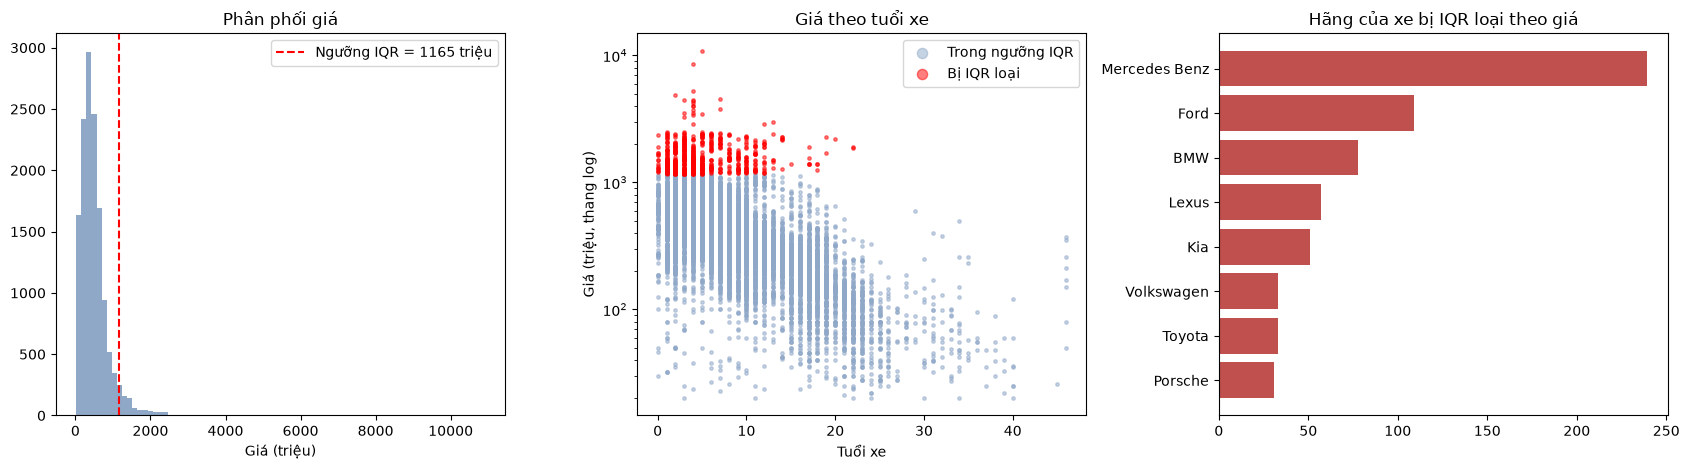

In [8]:
q1, q3 = df["price_million"].quantile(0.25), df["price_million"].quantile(0.75)
p_lo, p_hi = max(q1 - 1.5 * (q3 - q1), 20), q3 + 1.5 * (q3 - q1)
df["price_out"] = (df["price_million"] < p_lo) | (df["price_million"] > p_hi)
print(f"Ngưỡng IQR của giá: {p_lo:.0f} - {p_hi:.0f} triệu -> {df['price_out'].sum()} xe nằm ngoài ({df['price_out'].mean():.1%})")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].hist(df["price_million"], bins=80, color="#8fa8c8")
ax[0].axvline(p_hi, color="red", ls="--", label=f"Ngưỡng IQR = {p_hi:.0f} triệu")
ax[0].set_title("Phân phối giá"); ax[0].set_xlabel("Giá (triệu)"); ax[0].legend()

for flag, color, label in [(False, "#8fa8c8", "Trong ngưỡng IQR"), (True, "red", "Bị IQR loại")]:
    s = df[df["price_out"] == flag]
    ax[1].scatter(s["car_age"], s["price_million"], s=6, alpha=0.5, c=color, label=label)
ax[1].set_yscale("log"); ax[1].set_xlabel("Tuổi xe"); ax[1].set_ylabel("Giá (triệu, thang log)")
ax[1].set_title("Giá theo tuổi xe"); ax[1].legend(markerscale=3)

top = df[df["price_out"]]["carbrand_name"].value_counts().head(8)
ax[2].barh(top.index[::-1], top.values[::-1], color="#c0504d")
ax[2].set_title("Hãng của xe bị IQR loại theo giá")
plt.tight_layout(); plt.show()

### So giá với các xe cùng dòng
`ratio` = giá / giá trung vị của cùng dòng xe. Xe đắt nhưng `ratio` gần 1 nghĩa là dòng xe đó vốn đắt (giá hợp lý). Chỉ xét dòng xe có ít nhất 10 tin.

Xe bị IQR loại theo giá và đủ dữ liệu so sánh: 625
-> 72% trong số đó có giá lệch tối đa 2 lần so với trung vị cùng dòng xe (nhiều khả năng là xe đắt thật)
Xe nghi ngáo giá (giá > 3 lần hoặc < 1/3 trung vị cùng dòng): 559 (4.3%)


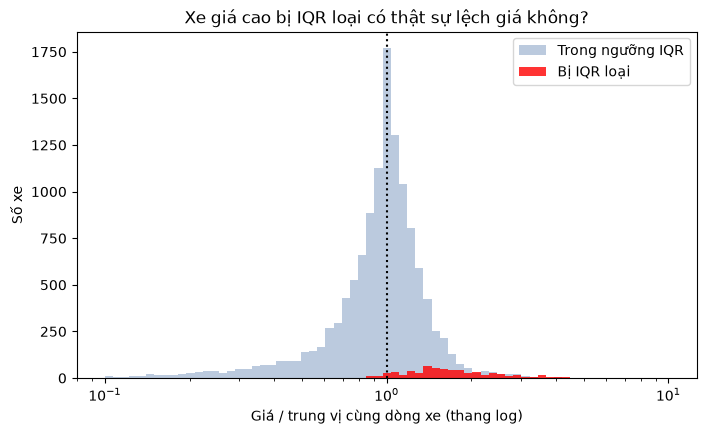


Xe giá cao nhất:


,subject,carbrand_name,mfdate,odo_km,price_million
13584,Bentley Flying Spur V8 2021 Xanh Muliner Anh Quốc,Bentley,2021,12000.0,10900.0
5978,Land Rover Range Rover SE LWB 2023 Bank 90%,LandRover,2022,22000.0,8599.0
13582,Lexus LM 350 2022 Trắng Tự động 8 cấp,Lexus,2022,22000.0,5250.0
2796,BMW X7 Pure Excellence LCI 2024 Đen,BMW,2024,7000.0,4899.0
7649,Range Rover Autobiography LWB 2019 Trắng,LandRover,2019,60079.0,4550.0


In [9]:
g = df.groupby(["carbrand_name", "carmodel_name"])["price_million"]
df["model_n"] = g.transform("size")
df["model_median"] = g.transform("median")
df["ratio"] = df["price_million"] / df["model_median"]
ok = df["model_n"] >= 10

out_ok = df[df["price_out"] & ok]
legit = out_ok["ratio"].between(0.5, 2).mean() if len(out_ok) else float("nan")
suspect = ok & ((df["ratio"] > 3) | (df["ratio"] < 1 / 3))
print(f"Xe bị IQR loại theo giá và đủ dữ liệu so sánh: {len(out_ok)}")
print(f"-> {legit:.0%} trong số đó có giá lệch tối đa 2 lần so với trung vị cùng dòng xe (nhiều khả năng là xe đắt thật)")
print(f"Xe nghi ngáo giá (giá > 3 lần hoặc < 1/3 trung vị cùng dòng): {suspect.sum()} ({suspect.sum() / ok.sum():.1%})")

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.logspace(-1, 1, 70)
ax.hist(df.loc[ok & ~df["price_out"], "ratio"], bins=bins, alpha=0.6, label="Trong ngưỡng IQR", color="#8fa8c8")
ax.hist(df.loc[ok & df["price_out"], "ratio"], bins=bins, alpha=0.8, label="Bị IQR loại", color="red")
ax.set_xscale("log"); ax.axvline(1, color="k", ls=":")
ax.set_xlabel("Giá / trung vị cùng dòng xe (thang log)"); ax.set_ylabel("Số xe")
ax.set_title("Xe giá cao bị IQR loại có thật sự lệch giá không?"); ax.legend()
plt.show()

print("\nXe giá cao nhất:")
df.nlargest(5, "price_million")[["subject", "carbrand_name", "mfdate", "odo_km", "price_million"]]

## 2. ODO: lọc theo km mỗi năm thay vì IQR
IQR chỉ nhìn ODO đứng một mình, không biết xe bao nhiêu tuổi: xe 20 tuổi chạy 250.000 km (bình thường) bị xóa, còn xe 2 tuổi chạy 150.000 km (vô lý) lại được giữ. Chia ODO cho tuổi xe để ra **km mỗi năm** thì so sánh được xe mới với xe cũ (xe 0 tuổi tính như 1 tuổi).

Loại các xe:
- Chạy quá nhiều: trên 50.000 km/năm, hoặc ODO trên 500.000 km (các số nhập cho có).
- Chạy quá ít: từ 2 tuổi trở lên mà dưới 1.000 km/năm (người đăng chưa nhập số km thật).

Quá cao: 285 | Quá thấp: 1040 | Tổng loại: 1325


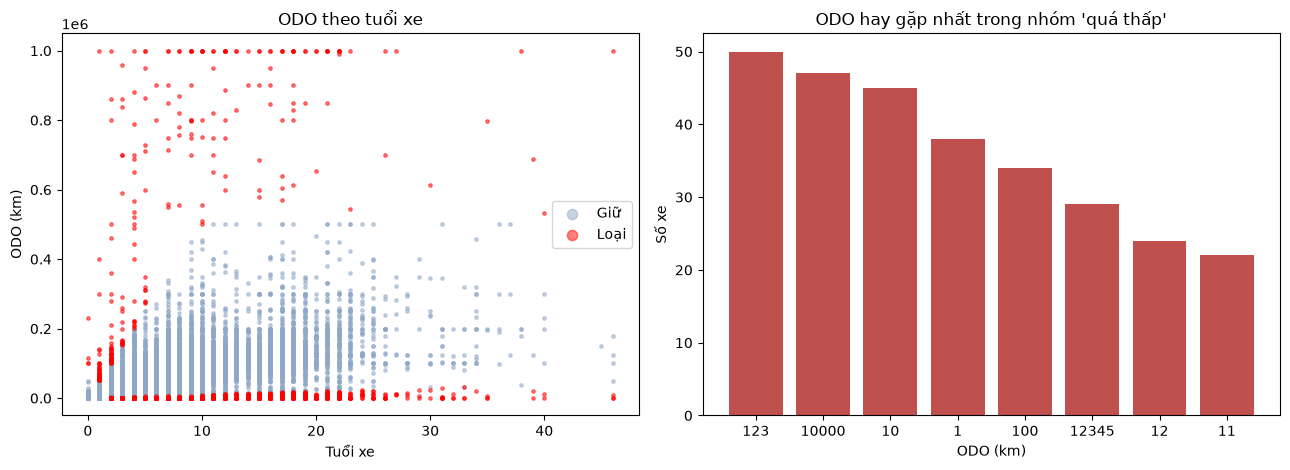

In [10]:
df["km_per_year"] = df["odo_km"] / df["car_age"].clip(lower=1)

too_high = (df["km_per_year"] > 50000) | (df["odo_km"] > 500000)
too_low = (df["car_age"] >= 2) & (df["km_per_year"] < 1000)
df["odo_bad"] = too_high | too_low
print(f"Quá cao: {too_high.sum()} | Quá thấp: {too_low.sum()} | Tổng loại: {df['odo_bad'].sum()}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for flag, color, label in [(False, "#8fa8c8", "Giữ"), (True, "red", "Loại")]:
    s = df[df["odo_bad"] == flag]
    ax[0].scatter(s["car_age"], s["odo_km"], s=6, alpha=0.5, c=color, label=label)
ax[0].set_xlabel("Tuổi xe"); ax[0].set_ylabel("ODO (km)"); ax[0].set_title("ODO theo tuổi xe"); ax[0].legend(markerscale=3)

common = df[too_low]["odo_km"].value_counts().head(8)
ax[1].bar(common.index.astype(int).astype(str), common.values, color="#c0504d")
ax[1].set_title("ODO hay gặp nhất trong nhóm 'quá thấp'"); ax[1].set_xlabel("ODO (km)"); ax[1].set_ylabel("Số xe")
plt.tight_layout(); plt.show()

## 3. Quyết định
- **Giá: không cắt.** Khoảng 72% xe nằm ngoài ngưỡng IQR có giá lệch tối đa 2 lần so với trung vị cùng dòng xe, và đa số là Mercedes, BMW, Lexus, Porsche. Xe giá cao nhất (Bentley Flying Spur, Range Rover, Lexus LM) có giá đúng với dòng xe. Cắt sẽ làm mô hình mất nhóm xe sang. Xe nghi ngáo giá (lệch hơn 3 lần so với cùng dòng) chiếm khoảng 4,3%, nằm cả hai phía, IQR toàn cục không xử lý được nên giữ lại và ghi nhận.
- **ODO: lọc theo km mỗi năm.** Nhóm "quá thấp" gồm các số như 1, 10, 100, 123, 12345, 10000: đây là số người đăng nhập cho có. Ngưỡng 1.000 km/năm được chọn vì hạ xuống 500 hay 300 chỉ thêm rất ít xe, còn nâng lên 2.000 thì bắt đầu loại nhầm xe ít chạy thật.
- **Hạn chế:** xe còn mới (dưới 2 tuổi) hoặc xe cũ nhưng ODO giả đúng bằng mức bình thường thì không phát hiện được.

In [11]:
before = len(df)
df = df[~df["odo_bad"]]
print(f"Số dòng trước: {before} | sau: {len(df)} | đã loại: {before - len(df)}")

df = df.drop(columns=["price_out", "model_n", "model_median", "ratio", "km_per_year", "odo_bad"])
df[["price_million", "car_age", "odo_km"]].describe()

Số dòng trước: 13819 | sau: 12494 | đã loại: 1325


,price_million,car_age,odo_km
count,12494.000000,12494.000000,12494.000000
mean,516.342953,7.769409,81552.610693
std,396.044710,5.974469,61555.472017
min,20.000000,0.000000,1.000000
25%,279.000000,3.000000,38000.000000
50%,435.000000,6.000000,72000.000000
75%,639.000000,10.000000,105990.750000
max,10900.000000,46.000000,500000.000000


## 4. Xuất file cho nhóm

In [12]:
df.to_csv("cars_cleaned.csv", index=False, encoding="utf-8-sig")
print("Đã lưu cars_cleaned.csv:", df.shape)
print(f"Tổng: {raw_rows} dòng thô -> {rows_from_sql} sau SQL -> {len(df)} file cuối")

Đã lưu cars_cleaned.csv: (12494, 21)
Tổng: 15000 dòng thô -> 13819 sau SQL -> 12494 file cuối
